In [16]:
from qiskit.visualization import plot_bloch_vector
from matplotlib.animation import FuncAnimation
from qiskit.visualization.bloch import Bloch
from IPython.display import Image, display  
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
import matplotlib.pyplot as plt
import numpy as np

def vector_xyz(state):
    """
    Function to translate a complex state into a 3D real vector.
    """
    
# Extract the complex amplitudes (alpha and beta)
    alpha = state.data[0]
    beta = state.data[1]

    # Compute Cartesian (x, y, z) coordinates 
    x = 2 * np.real(np.conj(alpha) * beta)
    y = 2 * np.imag(np.conj(alpha) * beta)
    z = np.abs(alpha)**2 - np.abs(beta)**2

    return([x, y, z])

In [17]:
def gates(gate_list, qc = QuantumCircuit(1)):
    """
    Function to apply a list of gates to a qubit.
    """
    states = []
    
    for gate_name in gate_list:
        # Check if the QuantumCircuit object has the requested gate method
        if hasattr(qc, gate_name):
            # Fetch the method (e.g., circuit.h, circuit.cx)
            gate_method = getattr(qc, gate_name)
            # Call the method, unpacking the target qubits
            gate_method(0)
            state = vector_xyz(Statevector(qc))
            states.append(state)
        else:
            print(f"Warning: Gate '{gate_name}' is not a recognized Qiskit method.")

    return states

In [18]:
def update(frame, gate_list):
    """
    Function to change the animation to the next frame.
    """
    b.vectors = []  # Clear previous frame vector paths cleanly

    states = gates(gate_list)
    moving_vector = states[frame]
    b.vectors = list(background_note_vectors)
    b.add_vectors(moving_vector)
    
    b.vector_color = ["#1572A1"]
    b.vector_width = 4.0
    
    gate_color = ["#FF5733"]  # High-contrast orange/red for the moving gate vector
    b.vector_color = background_colors + gate_color
    
    # Use different line widths to separate the layers
    b.vector_width = 1.5  # Base width for background elements
    
    # Render the combined canvas scene
    b.render()
    b.render()
    
    # Hide default text elements
    for text_obj in b.axes.texts:
        if text_obj.get_text() in ['x', 'y', 'z']:
            text_obj.set_visible(False)
            
    return b.axes.artists
            

In [19]:
def spherical_to_cartesian(r, theta, phi):
    """
    Spherical to Cartesian coordinates for setup.
    """
    x = r * np.sin(theta) * np.cos(phi)
    y = r * np.sin(theta) * np.sin(phi)
    z = r * np.cos(theta)
    return [x, y, z]

(-0.9, 0.9)

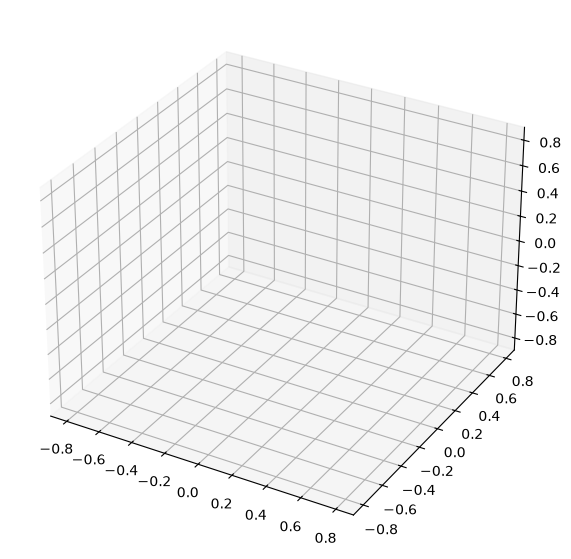

In [20]:
# Set up a 3D canvas, Bloch sphere, background musical vectors.

fig, ax = plt.subplots(subplot_kw=dict(projection="3d", computed_zorder=False), figsize=(7, 7))
b = Bloch(axes=ax)

# Arrays for notes and colour mapping.
notes = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]
octave_colours = ["#1572A1", "#9AD0EC", "#002B5B"]
all_vector_colours = []

# Assign even spaced locations for each musical vector.
for j in [3, 1, 2]:
    octave = {}
    for i in range(0, 12):
        r = 1
        theta = j * np.pi / 4
        phi = (i / 6) * np.pi
        x, y, z = spherical_to_cartesian(r, theta, phi)
            
        octave[notes[i]] = [x, y, z]
        all_vector_colours.append(octave_colours[j-1])
    
    # Sequentially add vectors and text annotations
    for label, coords in octave.items():
        if j == 2:
            b.add_annotation(coords, label) # Annotations for middle octave.
            b.add_vectors(coords)
        else:
            b.add_vectors(coords)

background_note_vectors = list(b.fixed_vectors) if hasattr(b, 'fixed_vectors') and b.fixed_vectors else list(b.vectors)
background_colors = list(all_vector_colours)

# Setup padding boundaries
limit = 0.9
ax.set_xlim3d(-limit, limit)
ax.set_ylim3d(-limit, limit)
ax.set_zlim3d(-limit, limit)


Please input gates as required. xxxxyyhzxx


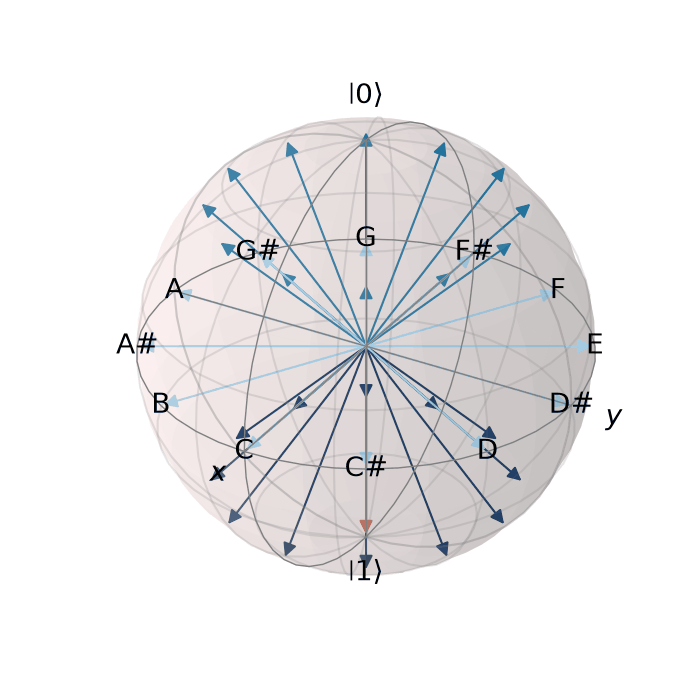

In [28]:
# Frame configurations
gate_list = list(input("Please input gates as required."))
frames_count = len(gate_list)  # Sliced frame count slightly so it compiles instantly

# Build the animation tracking pipeline
ani = FuncAnimation(fig, update, frames=frames_count, fargs=(gate_list,), interval=200, blit=True)

# SAVE AS A LOCAL GIF FILE
gif_path = "bloch_animation_gates.gif"
ani.save(gif_path, writer='pillow', fps=3)

# DISPLAY THE COPIED GIF DIRECTLY IN JUPYTER
display(Image(filename=gif_path))